In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder,StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.utils import to_categorical


In [25]:
df=pd.read_csv('small_iris_dataset_ann.csv')

In [26]:
df.head()

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,4.3,3.0,1.1,0.1,setosa
1,5.1,3.4,1.5,0.2,setosa
2,4.8,3.1,1.6,0.2,setosa
3,4.8,3.0,1.4,0.3,setosa
4,5.1,3.5,1.4,0.3,setosa


In [27]:
df['species'].values

array(['setosa', 'setosa', 'setosa', 'setosa', 'setosa', 'setosa',
       'setosa', 'setosa', 'setosa', 'setosa', 'versicolor', 'versicolor',
       'versicolor', 'versicolor', 'versicolor', 'versicolor',
       'versicolor', 'versicolor', 'versicolor', 'versicolor',
       'virginica', 'virginica', 'virginica', 'virginica', 'virginica',
       'virginica', 'virginica', 'virginica', 'virginica', 'virginica'],
      dtype=object)

In [28]:
df['species'].value_counts

<bound method IndexOpsMixin.value_counts of 0         setosa
1         setosa
2         setosa
3         setosa
4         setosa
5         setosa
6         setosa
7         setosa
8         setosa
9         setosa
10    versicolor
11    versicolor
12    versicolor
13    versicolor
14    versicolor
15    versicolor
16    versicolor
17    versicolor
18    versicolor
19    versicolor
20     virginica
21     virginica
22     virginica
23     virginica
24     virginica
25     virginica
26     virginica
27     virginica
28     virginica
29     virginica
Name: species, dtype: object>

In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   sepal_length_cm  30 non-null     float64
 1   sepal_width_cm   30 non-null     float64
 2   petal_length_cm  30 non-null     float64
 3   petal_width_cm   30 non-null     float64
 4   species          30 non-null     object 
dtypes: float64(4), object(1)
memory usage: 1.3+ KB


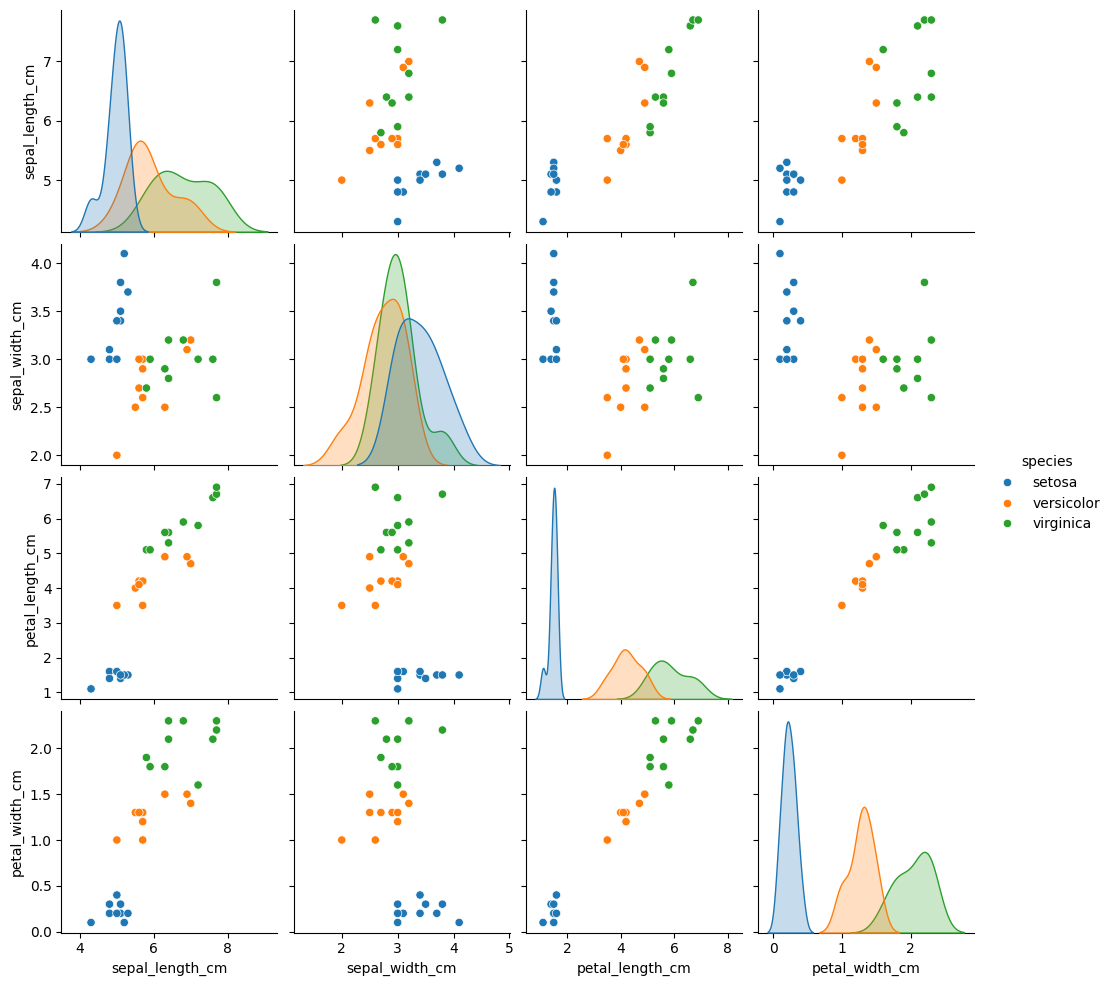

In [30]:
sns.pairplot(df, hue='species')

In [35]:
x=df.drop(columns=['species'],axis=1)
y=df['species']

In [32]:
encoder=LabelEncoder()
y_int=encoder.fit_transform(y)


In [33]:
y_int

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2])

In [38]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    X,
    y_int,
    test_size=0.2,
    random_state=42
)

In [39]:
scalar=StandardScaler()
x_train=scalar.fit_transform(x_train)
x_test=scalar.transform(x_test)

In [43]:
perceptron=Perceptron(max_iter=1000,random_state=42)
perceptron.fit(x_train,y_train)

Perceptron(random_state=42)

In [44]:
y_pred_perceptron=perceptron.predict(x_test)

In [45]:
accuracy_score(y_test,y_pred_perceptron)

0.6666666666666666

In [46]:
print(classification_report(y_test,y_pred_perceptron))

              precision    recall  f1-score   support

           0       0.67      1.00      0.80         2
           1       0.00      0.00      0.00         2
           2       0.67      1.00      0.80         2

    accuracy                           0.67         6
   macro avg       0.44      0.67      0.53         6
weighted avg       0.44      0.67      0.53         6



In [47]:
y_train_cat=to_categorical(y_train)
y_test_cat=to_categorical(y_test)

In [48]:
y_train_cat

array([[0., 0., 1.],
       [0., 0., 1.],
       [0., 1., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       [0., 1., 0.],
       [1., 0., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 0., 1.],
       [1., 0., 0.],
       [1., 0., 0.],
       [0., 0., 1.],
       [1., 0., 0.],
       [0., 0., 1.],
       [0., 0., 1.],
       [0., 1., 0.],
       [0., 0., 1.],
       [0., 0., 1.],
       [1., 0., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [1., 0., 0.]])

In [49]:
y_test_cat

array([[0., 0., 1.],
       [0., 1., 0.],
       [0., 0., 1.],
       [0., 1., 0.],
       [1., 0., 0.],
       [1., 0., 0.]])

In [50]:
model=Sequential()
model.add(Dense(10,activation='relu',input_dim=4))
model.add(Dense(10,activation='relu'))
model.add(Dense(3,activation='softmax'))

In [52]:
model.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

In [53]:
history=model.fit(x_train,y_train_cat,epochs=100,batch_size=10,validation_split=0.2,verbose=1)

Epoch 1/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 351ms/step - accuracy: 0.2632 - loss: 1.2119 - val_accuracy: 0.6000 - val_loss: 1.0198
Epoch 2/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.2632 - loss: 1.1972 - val_accuracy: 0.6000 - val_loss: 1.0206
Epoch 3/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.2632 - loss: 1.1811 - val_accuracy: 0.6000 - val_loss: 1.0212
Epoch 4/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.2632 - loss: 1.1663 - val_accuracy: 0.6000 - val_loss: 1.0219
Epoch 5/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step - accuracy: 0.2632 - loss: 1.1539 - val_accuracy: 0.6000 - val_loss: 1.0229
Epoch 6/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.2632 - loss: 1.1382 - val_accuracy: 0.6000 - val_loss: 1.0236
Epoch 7/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.2632 - loss: 1.1259 - val_accuracy: 0.6000 - val_loss: 1.0245
Epoch 8/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.2632 - loss: 1.1122 - val_accuracy: 0.6000 - val_los

In [56]:
loss,accuracy=model.evaluate(x_test,y_test_cat,verbose=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step - accuracy: 0.8333 - loss: 0.6559


In [57]:
print(accuracy)

0.8333333134651184


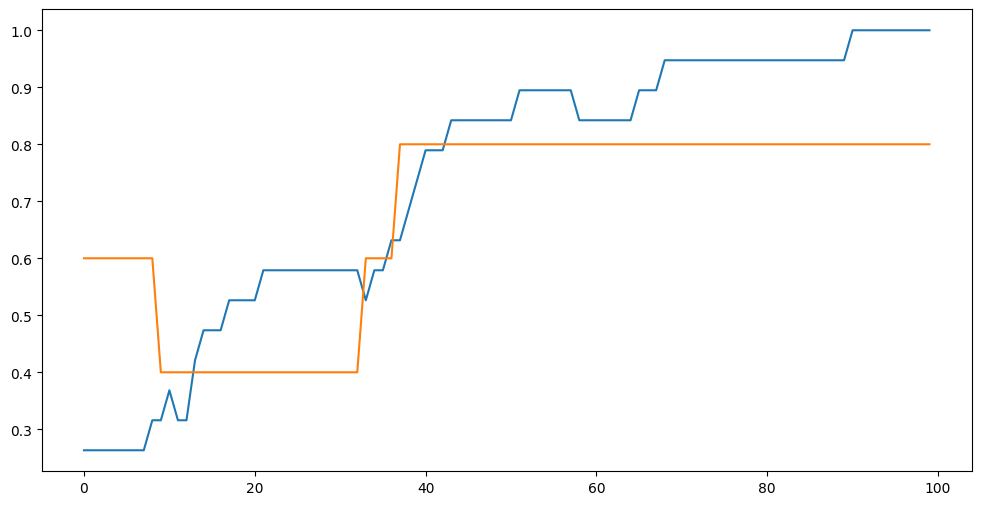

In [58]:
plt.figure(figsize=(12,6))
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])